# PD Scorecard: WoE / IV + Logistic Regression

> **What it does:** builds a classic application-style credit scorecard in Python from scratch: monotonic optimal binning, weight of evidence (WoE) and information value (IV), a stepwise logistic regression on WoE, and points scaling. It then validates it the way a model-risk team would (Gini, KS, bootstrap confidence intervals, calibration, PSI), compares it with a LightGBM challenger, sets a cutoff, produces adverse-action reason codes and runs a fair-lending check.
> **Data:** the UCI *Default of Credit Card Clients* dataset: 30,000 Taiwanese card holders, six months of repayment history and default on the next payment (`ucimlrepo`, with the UCI mirror on Kaggle as a fallback).
> **Methods:** chi-square-merged monotonic binning written by hand; WoE/IV; forward stepwise logistic regression with sign and VIF checks; 600 points at 50:1 odds and 20 points to double the odds; ROC/Gini/KS with bootstrap intervals; Hosmer–Lemeshow; PSI; LightGBM challenger; DuckDB strategy table; ECOA-style reason codes and adverse-impact ratios.
> **Key output:** the scorecard points table; validation metrics and their confidence intervals; the accuracy given up for interpretability; the cutoff strategy; and the fair-lending check.

## 1. Why a points scorecard is still the benchmark

Most retail and SME PD models in banks and development-finance institutions are still **logistic regressions on binned, WoE-transformed variables**, turned into a points table. Gradient boosting usually ranks a little better, but a scorecard has properties that supervisors and credit committees value:

- every characteristic has a monotonic, explainable effect, and the points can be read by a loan officer;
- it is stable through time because the bins absorb outliers;
- it produces **reason codes** for declined applicants, which U.S. law requires (ECOA / Regulation B adverse-action notices);
- it is easy to validate and monitor.

This notebook builds one end to end and measures how much accuracy that transparency costs. Every step is written explicitly.

## 2. Theory in brief

- **Weight of evidence** of bin $b$: $\mathrm{WoE}_b=\ln\dfrac{\%\text{good}_b}{\%\text{bad}_b}$. Positive WoE means safer than average.
- **Information value:** $\mathrm{IV}=\sum_b(\%\text{good}_b-\%\text{bad}_b)\,\mathrm{WoE}_b$. Rules of thumb: below 0.02 useless, 0.02–0.1 weak, 0.1–0.3 medium, above 0.3 strong, above 0.5 suspiciously strong.
- **Model:** $\ln\dfrac{P(\text{bad})}{P(\text{good})}=\alpha+\sum_j\beta_j\,\mathrm{WoE}_j$. Because WoE already points in the "good" direction, every $\beta_j$ must be **negative**; a positive sign means collinearity is distorting the variable.
- **Points:** with $\text{factor}=\text{PDO}/\ln 2$ and $\text{offset}=600-\text{factor}\cdot\ln 50$, the score is $\text{offset}+\text{factor}\cdot\ln(\text{odds of good})$. Each attribute contributes $-\text{factor}\,\beta_j\,\mathrm{WoE}_{jb}$ plus an equal share of the intercept.
- **Gini** $=2\,\text{AUC}-1$; **KS** is the maximum distance between the cumulative score distributions of goods and bads; **PSI** $=\sum(a_i-e_i)\ln(a_i/e_i)$ over score bands.

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import) ---------------
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the kernel crashed".
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library ---------------------------------------------------------
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party ---------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import lightgbm as lgb
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError("FRED_API_KEY not found. Create the .env file at the repo root (see .env.example).")
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0 Safari/537.36"}

SEED = 42
TEST_SHARE = 0.30
PDO, POINTS0, ODDS0 = 20, 600, 50          # 600 points at 50:1 good:bad odds; 20 points double the odds
IV_MIN, CORR_MAX, VIF_MAX = 0.02, 0.70, 5.0
MAX_BINS, MIN_BIN_SHARE = 6, 0.05
TARGET_APPROVAL = 0.70                     # the business approves the best 70% of applicants
PROTECTED = ["SEX", "MARRIAGE", "AGE"]     # never model inputs (ECOA / Reg B); used only for the fair-lending check

print(f"statsmodels {sm.__version__} · lightgbm {lgb.__version__} · duckdb {duckdb.__version__} · run on {dt.date.today():%Y-%m-%d}")

statsmodels 0.15.0 · lightgbm 4.7.0 · duckdb 1.5.6 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours ----------
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if path.exists() and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours:
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(f"⚠️  {name}: download failed ({type(err).__name__}); using cached copy")
            return pd.read_parquet(path)
        raise


# --- Chart style -------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "lines.linewidth": 2.0, "font.size": 10, "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """Interactive HTML always; static PNG (for GitHub) when kaleido can find Chrome."""
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run `plotly_get_chrome` once.")


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

# --- Kaggle downloads ------------------------------------------------------------------------
# The kaggle package authenticates with KAGGLE_API_TOKEN (read from .env above) or with
# ~/.kaggle/access_token / ~/.kaggle/kaggle.json. It is imported here, after load_dotenv, on purpose.
import zipfile


def kaggle_api():
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()
    return api


def kaggle_file(ref, filename, competition=False):
    """Download one file of a Kaggle dataset or competition into data/ (once) and return its local path."""
    target = DATA_DIR / filename
    if target.exists():
        return target
    api = kaggle_api()
    if competition:
        api.competition_download_file(ref, filename, path=DATA_DIR, quiet=True)
    else:
        api.dataset_download_file(ref, filename, path=DATA_DIR, quiet=True)
    zipped = DATA_DIR / f"{Path(filename).name}.zip"
    if zipped.exists():                                    # large files arrive zipped
        with zipfile.ZipFile(zipped) as z:
            z.extractall(DATA_DIR)
        zipped.unlink()
    if not target.exists():
        raise FileNotFoundError(f"{filename} not found after download from {ref}")
    return target

## 4. Data

The dataset is downloaded from the UCI repository with `ucimlrepo`. If the UCI site is unreachable, the identical file is taken from UCI's own mirror on Kaggle (`uciml/default-of-credit-card-clients-dataset`). The repayment-status codes are: −2 no consumption, −1 paid in full, 0 revolving credit used and minimum paid, 1–8 months of payment delay.

In [3]:
NAMES = (["LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE", "PAY_1", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
         + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)])


def fetch_uci():
    from ucimlrepo import fetch_ucirepo
    d = fetch_ucirepo(id=350)
    X = d.data.features.copy()
    X.columns = NAMES                                  # X1..X23 in the documented order
    return X.assign(default=d.data.targets.iloc[:, 0].to_numpy())


def fetch_kaggle_mirror():
    raw = pd.read_csv(kaggle_file("uciml/default-of-credit-card-clients-dataset", "UCI_Credit_Card.csv"))
    raw = raw.rename(columns={"PAY_0": "PAY_1", "default.payment.next.month": "default"}).drop(columns="ID")
    return raw[NAMES + ["default"]]


def fetch_data():
    try:
        return fetch_uci()
    except Exception as err:
        print(f"UCI repository unreachable ({type(err).__name__}); using the UCI mirror on Kaggle")
        return fetch_kaggle_mirror()


df = cached("taiwan_credit_default", fetch_data, max_age_hours=24 * 365).astype(float)
df["default"] = df["default"].astype(int)
print(f"{len(df):,} clients · default rate {df['default'].mean():.1%}")
df.describe().T[["mean", "min", "50%", "max"]].round(1)

30,000 clients · default rate 22.1%


,mean,min,50%,max
LIMIT_BAL,"167,484.30","10,000.00","140,000.00","1,000,000.00"
SEX,1.60,1.00,2.00,2.00
EDUCATION,1.90,0.00,2.00,6.00
MARRIAGE,1.60,0.00,2.00,3.00
AGE,35.50,21.00,34.00,79.00
PAY_1,-0.00,-2.00,0.00,8.00
PAY_2,-0.10,-2.00,0.00,8.00
PAY_3,-0.20,-2.00,0.00,8.00
PAY_4,-0.20,-2.00,0.00,8.00
PAY_5,-0.30,-2.00,0.00,8.00


### Engineered characteristics

Six months of history allow a few behavioural summaries that scorecard developers routinely build: utilisation of the limit, the share of last month's bill that was repaid, how many of the six months were delinquent, the worst delinquency, and the bill trend.

In [4]:
pay_cols = [f"PAY_{i}" for i in range(1, 7)]
df["util_1"] = df["BILL_AMT1"] / df["LIMIT_BAL"]
df["avg_util_6m"] = df[[f"BILL_AMT{i}" for i in range(1, 7)]].mean(axis=1) / df["LIMIT_BAL"]
df["pay_ratio_1"] = (df["PAY_AMT1"] / df["BILL_AMT2"].where(df["BILL_AMT2"] > 0)).clip(0, 2).fillna(1.0)   # paid this month / last bill
df["months_delinquent"] = (df[pay_cols] > 0).sum(axis=1)
df["max_delinquency"] = df[pay_cols].max(axis=1).clip(lower=0)
df["bill_trend"] = (df["BILL_AMT1"] - df["BILL_AMT6"]) / df["LIMIT_BAL"]
CANDIDATES = [c for c in df.columns if c not in PROTECTED + ["default", "EDUCATION"]]
train, test = train_test_split(df, test_size=TEST_SHARE, stratify=df["default"], random_state=SEED)
print(f"{len(CANDIDATES)} candidate characteristics (protected attributes and education excluded) · "
      f"train {len(train):,} ({train['default'].mean():.1%} bad) · test {len(test):,} ({test['default'].mean():.1%} bad)")

25 candidate characteristics (protected attributes and education excluded) · train 21,000 (22.1% bad) · test 9,000 (22.1% bad)


## 5. Monotonic binning, WoE and IV

The binning starts from up to 20 quantile bins and merges adjacent bins until (1) the bad rate moves in one direction only, (2) every bin holds at least 5% of the sample, and (3) there are at most six bins. At each step it merges the adjacent pair whose bad rates are the most similar (lowest chi-square), which is the logic of ChiMerge. The direction of the trend is taken from the rank correlation with default.

In [5]:
def bin_stats(x, y, edges):
    idx = np.searchsorted(edges, x, side="right") - 1
    g = pd.DataFrame({"b": idx, "y": y}).groupby("b")["y"].agg(["count", "sum"]).reindex(range(len(edges) - 1), fill_value=0)
    return g["count"].to_numpy(), g["sum"].to_numpy()


def chi2_pair(n1, b1, n2, b2):
    obs = np.array([[b1, n1 - b1], [b2, n2 - b2]], dtype=float) + 0.5
    exp = obs.sum(1, keepdims=True) * obs.sum(0, keepdims=True) / obs.sum()
    return ((obs - exp) ** 2 / exp).sum()


def monotonic_bins(x, y, max_bins=MAX_BINS, min_share=MIN_BIN_SHARE, n_pre=20):
    x, y = np.asarray(x, float), np.asarray(y, int)
    qs = np.unique(np.quantile(x, np.linspace(0, 1, n_pre + 1)[1:-1]))
    edges = np.concatenate([[-np.inf], qs, [np.inf]])
    n, b = bin_stats(x, y, edges)
    keep = n > 0                                            # drop empty pre-bins
    edges = np.concatenate([edges[:-1][keep], [np.inf]])
    direction = np.sign(np.nan_to_num(stats.spearmanr(x, y).statistic)) or 1.0
    while len(edges) > 2:
        n, b = bin_stats(x, y, edges)
        rate = b / n
        violating = [i for i in range(len(n) - 1) if direction * (rate[i + 1] - rate[i]) < 0]
        small = [i for i in range(len(n)) if n[i] < min_share * len(x)]
        if violating:
            cands = violating
        elif small:
            cands = sorted({min(max(i - 1, 0), len(n) - 2) for i in small} | {min(i, len(n) - 2) for i in small})
        elif len(n) > max_bins:
            cands = list(range(len(n) - 1))
        else:
            break
        i = min(cands, key=lambda k: chi2_pair(n[k], b[k], n[k + 1], b[k + 1]))
        edges = np.delete(edges, i + 1)                     # merge bin i with bin i+1
    return edges


def woe_table(x, y, edges):
    n, b = bin_stats(x, y, edges)
    g = n - b
    pg, pb = (g + 0.5) / (g.sum() + 0.5), (b + 0.5) / (b.sum() + 0.5)
    woe = np.log(pg / pb)
    labels = [f"[{edges[i]:,.3g}, {edges[i + 1]:,.3g})" for i in range(len(n))]
    t = pd.DataFrame({"bin": labels, "count": n, "share %": n / n.sum() * 100, "bad rate %": b / n * 100,
                      "WoE": woe, "IV contribution": (pg - pb) * woe})
    t.attrs["edges"], t.attrs["IV"] = edges, t["IV contribution"].sum()
    return t


def apply_woe(x, table):
    idx = np.searchsorted(table.attrs["edges"], np.asarray(x, float), side="right") - 1
    return table["WoE"].to_numpy()[np.clip(idx, 0, len(table) - 1)]


tables = {c: woe_table(train[c], train["default"], monotonic_bins(train[c], train["default"])) for c in CANDIDATES}
iv = pd.Series({c: t.attrs["IV"] for c, t in tables.items()}).sort_values(ascending=False)
iv_tab = pd.DataFrame({"IV": iv, "bins": [len(tables[c]) for c in iv.index],
                       "strength": pd.cut(iv, [-np.inf, 0.02, 0.1, 0.3, 0.5, np.inf],
                                          labels=["useless", "weak", "medium", "strong", "suspicious"])})
iv_tab.round(3)

,IV,bins,strength
months_delinquent,0.89,5,suspicious
PAY_1,0.88,4,suspicious
max_delinquency,0.78,3,suspicious
PAY_2,0.56,2,suspicious
PAY_3,0.42,3,strong
PAY_4,0.37,3,strong
PAY_5,0.34,3,strong
PAY_6,0.29,3,medium
pay_ratio_1,0.21,5,medium
LIMIT_BAL,0.19,6,medium


### Selection: IV, correlation, stepwise AIC, signs and VIF

1. Keep characteristics with IV ≥ 0.02.
2. Among pairs whose WoE values correlate above 0.7, keep the one with the higher IV (the repayment-status months are strongly correlated with each other).
3. Forward stepwise logistic regression by AIC.
4. Drop any variable with a positive coefficient or a VIF above 5, and refit.

In [6]:
W_tr = pd.DataFrame({c: apply_woe(train[c], tables[c]) for c in CANDIDATES}, index=train.index)
W_te = pd.DataFrame({c: apply_woe(test[c], tables[c]) for c in CANDIDATES}, index=test.index)
y_tr, y_te = train["default"].to_numpy(), test["default"].to_numpy()

pool = [c for c in iv.index if iv[c] >= IV_MIN]
corr = W_tr[pool].corr().abs()
kept = []
for c in pool:                                      # pool is sorted by IV, so the stronger variable survives
    if all(corr.loc[c, k] <= CORR_MAX for k in kept):
        kept.append(c)


def fit_logit(cols):
    return sm.Logit(y_tr, sm.add_constant(W_tr[cols])).fit(disp=0)


selected, best_aic = [], sm.Logit(y_tr, np.ones(len(y_tr))).fit(disp=0).aic     # start from the intercept-only model
while True:
    trials = {c: fit_logit(selected + [c]).aic for c in kept if c not in selected}
    if not trials:
        break
    c, aic = min(trials.items(), key=lambda kv: kv[1])
    if aic > best_aic - 2:                          # stop when AIC improves by less than 2
        break
    selected.append(c)
    best_aic = aic

while True:                                          # sign and VIF checks
    model = fit_logit(selected)
    coefs = model.params.drop("const")
    X_vif = sm.add_constant(W_tr[selected])
    vif = pd.Series([variance_inflation_factor(X_vif.values, i + 1) for i in range(len(selected))], index=selected)
    bad = list(coefs[coefs > 0].index) + list(vif[vif > VIF_MAX].index)
    if not bad:
        break
    selected.remove(max(bad, key=lambda c: (coefs[c] > 0, vif[c])))

print(f"IV ≥ {IV_MIN}: {len(pool)} · after correlation filter: {len(kept)} · final model: {len(selected)} characteristics")
pd.DataFrame({"coef": model.params, "std err": model.bse, "p-value": model.pvalues,
              "VIF": vif.reindex(model.params.index), "IV": iv.reindex(model.params.index)}).round(3)

IV ≥ 0.02: 19 · after correlation filter: 14 · final model: 9 characteristics


,coef,std err,p-value,VIF,IV
const,-1.26,0.02,0.00,NaN,NaN
months_delinquent,-0.84,0.02,0.00,1.32,0.89
LIMIT_BAL,-0.12,0.05,0.02,1.59,0.19
PAY_AMT3,-0.25,0.06,0.00,1.63,0.13
avg_util_6m,-0.64,0.07,0.00,1.48,0.09
PAY_AMT1,-0.25,0.05,0.00,1.54,0.17
PAY_AMT2,-0.24,0.06,0.00,1.57,0.16
PAY_AMT6,-0.22,0.08,0.00,1.65,0.10
bill_trend,-0.16,0.07,0.02,1.11,0.08
PAY_AMT4,-0.19,0.08,0.01,1.69,0.10


## 6. Points scaling

Each characteristic receives the points of its bin; the intercept is spread equally over the characteristics so that every applicant's score is simply the sum of their points.

In [7]:
factor = PDO / np.log(2)
offset = POINTS0 - factor * np.log(ODDS0)
alpha, k = model.params["const"], len(selected)
rows = []
for c in selected:
    t = tables[c]
    pts = -factor * model.params[c] * t["WoE"] + (offset - factor * alpha) / k
    r = t.assign(characteristic=c, points=np.round(pts).astype(int))[["characteristic", "bin", "share %", "bad rate %", "WoE", "points"]]
    r.attrs = {}                                     # bin edges live in `tables`; keep the points table plain
    rows.append(r)
scorecard = pd.concat(rows, ignore_index=True)


def score(frame):
    s = np.zeros(len(frame))
    for c in selected:
        t = scorecard[scorecard["characteristic"] == c]
        idx = np.searchsorted(tables[c].attrs["edges"], frame[c].to_numpy(float), side="right") - 1
        s += t["points"].to_numpy()[np.clip(idx, 0, len(t) - 1)]
    return s


s_tr, s_te = score(train), score(test)
pd_of = lambda s: 1 / (1 + np.exp((s - offset) / factor))          # PD implied by a score
print(f"Score range on test: {s_te.min():.0f}–{s_te.max():.0f} · median {np.median(s_te):.0f}")
scorecard.round(2)

Score range on test: 447–580 · median 540


,characteristic,bin,share %,bad rate %,WoE,points
0,months_delinquent,"[0, 1)",66.24,11.45,0.79,77
1,months_delinquent,"[1, 2)",14.80,29.95,-0.41,48
2,months_delinquent,"[2, 3)",6.38,39.66,-0.84,38
3,months_delinquent,"[3, 5)",7.13,53.94,-1.42,24
4,months_delinquent,"[5, inf)",5.45,68.36,-2.03,9
5,LIMIT_BAL,"[-inf, 5e+04)",14.42,36.89,-0.72,56
6,LIMIT_BAL,"[5e+04, 8e+04)",16.35,26.94,-0.26,57
7,LIMIT_BAL,"[8e+04, 1.4e+05)",17.58,23.73,-0.09,58
8,LIMIT_BAL,"[1.4e+05, 1.6e+05)",6.18,19.74,0.14,59
9,LIMIT_BAL,"[1.6e+05, 2.7e+05)",24.99,17.32,0.30,59


## 7. Validation

Discrimination on the hold-out sample with 1,000 bootstrap resamples for the confidence interval; calibration by decile with a Hosmer–Lemeshow statistic; and the population stability index between development and hold-out score distributions.

In [8]:
def ks_stat(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    return np.max(np.abs(tpr - fpr))


rng = np.random.default_rng(SEED)
risk_te = -s_te                                       # higher risk = lower score
boot = []
for _ in range(1_000):
    i = rng.integers(0, len(y_te), len(y_te))
    boot.append(2 * roc_auc_score(y_te[i], risk_te[i]) - 1)
gini_ci = np.percentile(boot, [2.5, 97.5])

dec = pd.qcut(s_te, 10, labels=False, duplicates="drop")
cal = pd.DataFrame({"score": s_te, "pd": pd_of(s_te), "y": y_te, "decile": dec}).groupby("decile").agg(
    clients=("y", "size"), min_score=("score", "min"), predicted_pd=("pd", "mean"), observed_dr=("y", "mean"))
hl = (((cal["observed_dr"] - cal["predicted_pd"]) * cal["clients"]) ** 2
      / (cal["clients"] * cal["predicted_pd"] * (1 - cal["predicted_pd"]))).sum()

bands = np.quantile(s_tr, np.linspace(0, 1, 11)); bands[0], bands[-1] = -np.inf, np.inf
e = np.histogram(s_tr, bands)[0] / len(s_tr); a = np.histogram(s_te, bands)[0] / len(s_te)
psi = np.sum((a - e) * np.log((a + 1e-6) / (e + 1e-6)))

validation = pd.DataFrame({
    "train": {"AUC": roc_auc_score(y_tr, -s_tr), "Gini": 2 * roc_auc_score(y_tr, -s_tr) - 1, "KS": ks_stat(y_tr, -s_tr)},
    "test": {"AUC": roc_auc_score(y_te, risk_te), "Gini": 2 * roc_auc_score(y_te, risk_te) - 1, "KS": ks_stat(y_te, risk_te)}}).T
print(f"Test Gini {validation.loc['test', 'Gini']:.3f} (95% bootstrap CI {gini_ci[0]:.3f}–{gini_ci[1]:.3f}) · "
      f"HL χ² {hl:.1f} (8 df, p = {1 - stats.chi2.cdf(hl, 8):.3f}) · PSI {psi:.4f}")
display(validation.round(3))
(cal.assign(predicted_pd=cal["predicted_pd"] * 100, observed_dr=cal["observed_dr"] * 100)
 .rename(columns={"predicted_pd": "predicted PD %", "observed_dr": "observed default %"}).round(1))

Test Gini 0.506 (95% bootstrap CI 0.482–0.530) · HL χ² 24.5 (8 df, p = 0.002) · PSI 0.0014


,AUC,Gini,KS
train,0.77,0.53,0.41
test,0.75,0.51,0.39


,clients,min_score,predicted PD %,observed default %
decile,,,,
0,903,447.00,63.20,60.80
1,926,486.00,42.10,41.70
2,900,504.00,30.60,28.60
3,928,520.00,18.80,23.10
4,960,535.00,14.80,14.70
5,989,541.00,12.60,15.30
6,778,546.00,11.20,11.60
7,933,549.00,10.00,10.00
8,853,553.00,8.60,7.20


### The price of interpretability: a LightGBM challenger

The challenger sees the same characteristics in raw form (no binning, no monotonicity) and is tuned lightly with early stopping on part of the training sample.

In [9]:
Xg_tr, Xg_val, yg_tr, yg_val = train_test_split(train[CANDIDATES], y_tr, test_size=0.2, stratify=y_tr, random_state=SEED)
gbm = lgb.LGBMClassifier(n_estimators=2_000, learning_rate=0.02, num_leaves=15, min_child_samples=100, subsample=0.8,
                         subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, verbose=-1)
gbm.fit(Xg_tr, yg_tr, eval_set=[(Xg_val, yg_val)], callbacks=[lgb.early_stopping(100, verbose=False)])
p_gbm = gbm.predict_proba(test[CANDIDATES])[:, 1]
boot_diff = []
for _ in range(1_000):
    i = rng.integers(0, len(y_te), len(y_te))
    boot_diff.append(2 * roc_auc_score(y_te[i], p_gbm[i]) - 2 * roc_auc_score(y_te[i], risk_te[i]))
challenger = pd.DataFrame({
    "scorecard": {"Gini": validation.loc["test", "Gini"], "KS": validation.loc["test", "KS"], "inputs": len(selected)},
    "LightGBM": {"Gini": 2 * roc_auc_score(y_te, p_gbm) - 1, "KS": ks_stat(y_te, p_gbm), "inputs": len(CANDIDATES)}}).T
print(f"LightGBM − scorecard Gini: {np.mean(boot_diff):+.3f} (95% CI {np.percentile(boot_diff, 2.5):+.3f} to {np.percentile(boot_diff, 97.5):+.3f})")
challenger.round(3)

LightGBM − scorecard Gini: +0.060 (95% CI +0.049 to +0.072)


,Gini,KS,inputs
scorecard,0.51,0.39,9.00
LightGBM,0.57,0.43,25.00


## 8. Cutoff strategy with SQL

The strategy table is the document a credit committee signs: for each score band, how many applicants are approved and what bad rate the approved book carries. It is built with DuckDB directly on the scored hold-out sample.

In [10]:
scored = test[PROTECTED].assign(score=s_te, bad=y_te)
con = duckdb.connect()
con.register("scored", scored)
strategy = con.execute("""
    WITH b AS (SELECT FLOOR(score / 10) * 10 AS band, COUNT(*) AS n, SUM(bad) AS bads FROM scored GROUP BY 1)
    SELECT band AS "score from", n AS clients, bads,
           100.0 * bads / n AS "band bad rate %",
           100.0 * SUM(n) OVER w / SUM(n) OVER () AS "approval rate % if cutoff here",
           100.0 * SUM(bads) OVER w / SUM(n) OVER w AS "bad rate of approved %"
    FROM b WINDOW w AS (ORDER BY band DESC ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW)
    ORDER BY band DESC""").df()
cutoff = float(np.quantile(s_te, 1 - TARGET_APPROVAL))
approved = s_te >= cutoff
print(f"Cutoff {cutoff:.0f} points → approval {approved.mean():.1%}, bad rate of approved {y_te[approved].mean():.1%} "
      f"(declined {y_te[~approved].mean():.1%}; portfolio {y_te.mean():.1%})")
strategy.round(1)

Cutoff 519 points → approval 70.2%, bad rate of approved 12.7% (declined 44.2%; portfolio 22.1%)


,score from,clients,bads,band bad rate %,approval rate % if cutoff here,bad rate of approved %
0,580.00,4,0.00,0.00,0.00,0.00
1,570.00,146,3.00,2.10,1.70,2.00
2,560.00,576,40.00,6.90,8.10,5.90
3,550.00,1608,129.00,8.00,25.90,7.40
4,540.00,2235,300.00,13.40,50.80,10.30
5,530.00,1368,253.00,18.50,66.00,12.20
6,520.00,334,74.00,22.20,69.70,12.70
7,510.00,529,134.00,25.30,75.60,13.70
8,500.00,716,252.00,35.20,83.50,15.80
9,490.00,450,194.00,43.10,88.50,17.30


## 9. Reason codes and the fair-lending check

**Reason codes.** For a declined applicant, each characteristic's shortfall is the gap between the maximum points available and the points received. The largest shortfalls are the principal reasons for the decision, which is how U.S. lenders generate adverse-action notices.

**Fair lending.** Sex, marital status and age were never model inputs, but a model can still produce disparate outcomes through correlated characteristics. The **adverse impact ratio** compares approval rates between groups; below 0.8 (the "four-fifths rule") the outcome would need justification.

In [11]:
max_pts = scorecard.groupby("characteristic")["points"].max()
declined = test[~approved]
short = pd.DataFrame(index=declined.index)
for c in selected:
    t = scorecard[scorecard["characteristic"] == c]
    idx = np.searchsorted(tables[c].attrs["edges"], declined[c].to_numpy(float), side="right") - 1
    short[c] = max_pts[c] - t["points"].to_numpy()[np.clip(idx, 0, len(t) - 1)]
top3 = short.apply(lambda r: list(r.nlargest(3).index), axis=1)          # the three reasons printed on the notice
top_reason = pd.DataFrame({
    "% of declines: principal reason": short.idxmax(axis=1).value_counts(normalize=True).mul(100),
    "% of declines: among top 3 reasons": pd.Series({c: top3.apply(lambda l: c in l).mean() * 100 for c in selected}),
    "average shortfall (points)": short.mean()}).fillna(0).sort_values("% of declines: among top 3 reasons", ascending=False)

grp = scored.assign(approved=approved, sex=scored["SEX"].map({1: "male", 2: "female"}),
                    age_band=pd.cut(scored["AGE"], [0, 30, 45, 60, 120], labels=["<30", "30–44", "45–59", "60+"]))
fair = []
for col in ["sex", "age_band"]:
    rates = grp.groupby(col, observed=True).agg(clients=("approved", "size"), approval=("approved", "mean"), bad_rate=("bad", "mean"))
    rates["adverse impact ratio"] = rates["approval"] / rates["approval"].max()
    fair.append(rates.assign(group=col).reset_index().rename(columns={col: "level"}))
fair = pd.concat(fair).set_index(["group", "level"])
display(top_reason.round(1))
fair.assign(approval=fair["approval"] * 100, bad_rate=fair["bad_rate"] * 100).rename(
    columns={"approval": "approval %", "bad_rate": "bad rate %"}).round(2)

,% of declines: principal reason,% of declines: among top 3 reasons,average shortfall (points)
months_delinquent,100.00,100.00,43.70
PAY_AMT2,0.00,76.20,9.90
PAY_AMT3,0.00,52.60,7.90
avg_util_6m,0.00,41.00,5.80
PAY_AMT1,0.00,29.60,8.10
PAY_AMT6,0.00,0.30,4.30
PAY_AMT4,0.00,0.30,4.30
LIMIT_BAL,0.00,0.00,2.30
bill_trend,0.00,0.00,1.30


clients  approval %  bad rate %  adverse impact ratio
group    level                                                        
sex      female     5437       70.87       20.99                  1.00
         male       3563       69.07       23.86                  0.97
age_band <30        3285       66.67       22.07                  0.91
         30–44      4262       73.13       20.69                  1.00
         45–59      1359       69.39       26.27                  0.95
         60+          94       68.09       28.72                  0.93

## 10. Charts

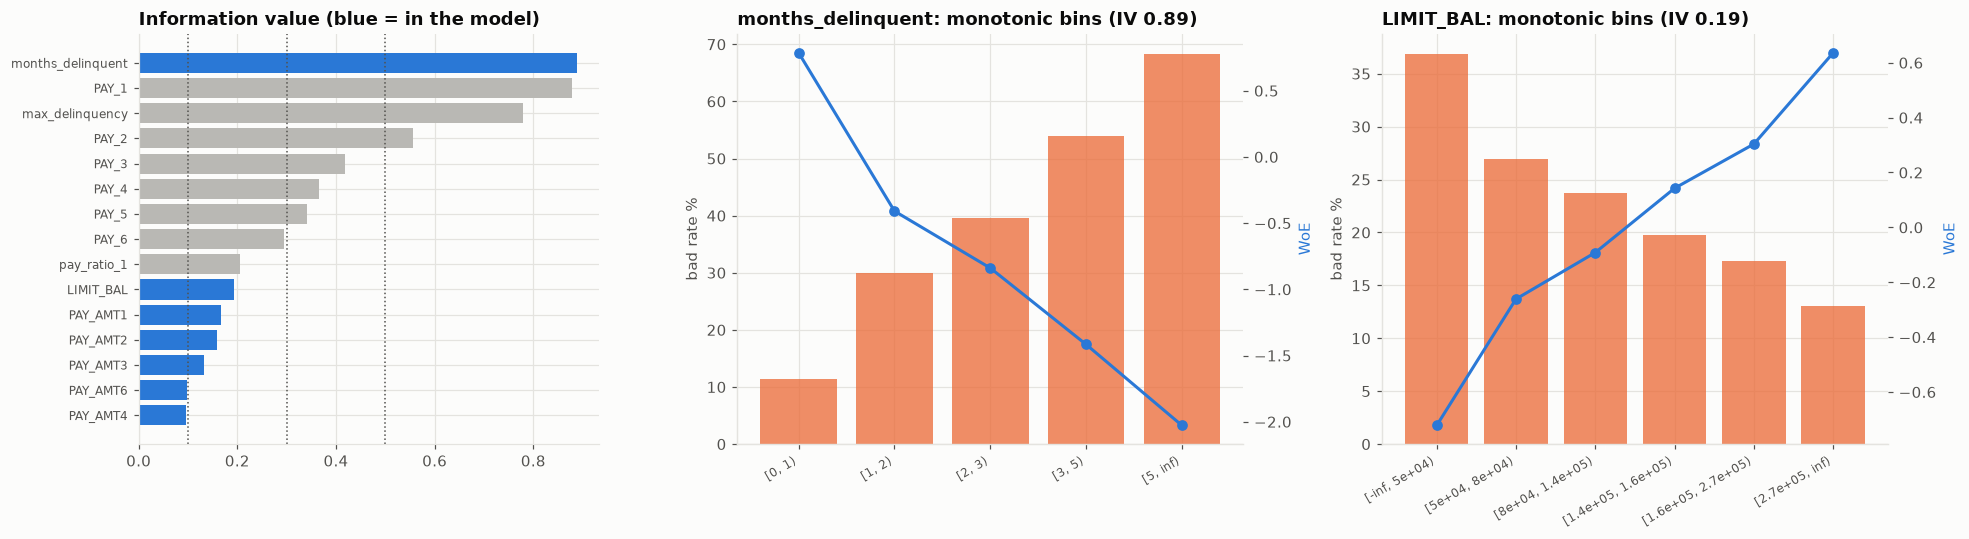

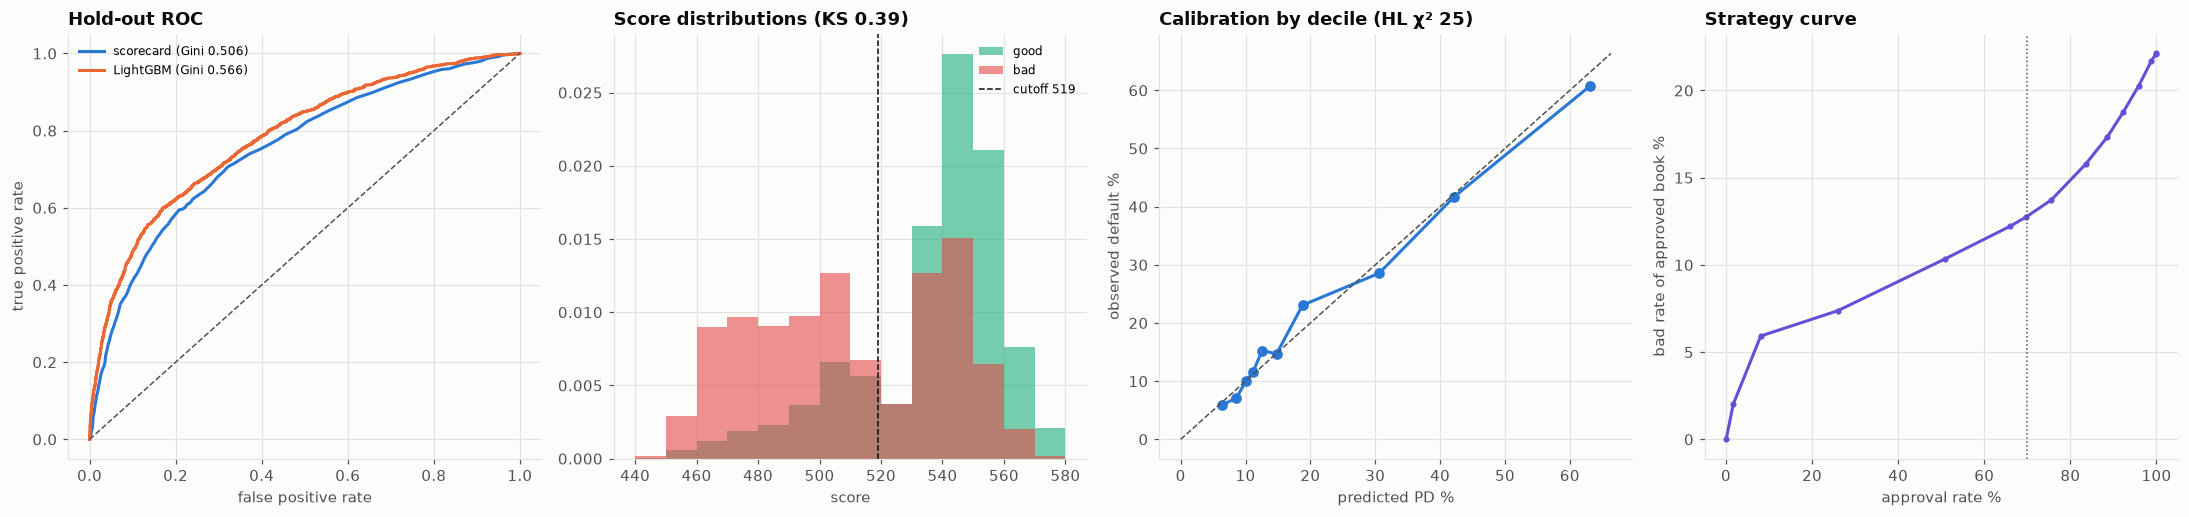

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
ax = axes[0]
top = iv_tab.head(15).iloc[::-1]
ax.barh(top.index, top["IV"], color=[PALETTE[0] if c in selected else "#b9b8b4" for c in top.index])
for x0, lab in [(0.1, "medium"), (0.3, "strong"), (0.5, "suspicious")]:
    ax.axvline(x0, color=INK_2, ls=":", lw=1)
ax.set_title("Information value (blue = in the model)")
ax.tick_params(axis="y", labelsize=8)
for ax, c in zip(axes[1:], selected[:2]):
    t = tables[c]
    ax.bar(range(len(t)), t["bad rate %"], color=PALETTE[1], alpha=0.75)
    ax2 = ax.twinx()
    ax2.plot(range(len(t)), t["WoE"], "o-", color=PALETTE[0])
    ax2.set_ylabel("WoE", color=PALETTE[0]); ax2.grid(False)
    ax.set_xticks(range(len(t)), t["bin"], rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("bad rate %")
    ax.set_title(f"{c}: monotonic bins (IV {t.attrs['IV']:.2f})")
plt.tight_layout()
save_fig(fig, "01_iv_and_woe")
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
ax = axes[0]
for lab, s, col in [("scorecard", risk_te, PALETTE[0]), ("LightGBM", p_gbm, PALETTE[1])]:
    fpr, tpr, _ = roc_curve(y_te, s)
    ax.plot(fpr, tpr, color=col, label=f"{lab} (Gini {2 * roc_auc_score(y_te, s) - 1:.3f})")
ax.plot([0, 1], [0, 1], color=INK_2, ls="--", lw=1)
ax.set_title("Hold-out ROC"); ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate"); ax.legend(fontsize=8)
ax = axes[1]
bins_ = np.arange(np.floor(s_te.min() / 10) * 10, s_te.max() + 10, 10)
ax.hist(s_te[y_te == 0], bins_, color=PALETTE[2], alpha=0.6, density=True, label="good")
ax.hist(s_te[y_te == 1], bins_, color=PALETTE[7], alpha=0.6, density=True, label="bad")
ax.axvline(cutoff, color=INK, ls="--", lw=1, label=f"cutoff {cutoff:.0f}")
ax.set_title(f"Score distributions (KS {validation.loc['test', 'KS']:.2f})"); ax.set_xlabel("score"); ax.legend(fontsize=8)
ax = axes[2]
ax.plot(cal["predicted_pd"] * 100, cal["observed_dr"] * 100, "o-", color=PALETTE[0])
lim = max(cal["predicted_pd"].max(), cal["observed_dr"].max()) * 105
ax.plot([0, lim], [0, lim], color=INK_2, ls="--", lw=1)
ax.set_title(f"Calibration by decile (HL χ² {hl:.0f})"); ax.set_xlabel("predicted PD %"); ax.set_ylabel("observed default %")
ax = axes[3]
ax.plot(strategy["approval rate % if cutoff here"], strategy["bad rate of approved %"], "o-", color=PALETTE[6], ms=3)
ax.axvline(TARGET_APPROVAL * 100, color=INK_2, ls=":", lw=1)
ax.set_title("Strategy curve"); ax.set_xlabel("approval rate %"); ax.set_ylabel("bad rate of approved book %")
plt.tight_layout()
save_fig(fig, "02_validation_and_strategy")
plt.show()

## 11. Reading the results and limitations

UCI Taiwan card holders, 21,000 for development and 9,000 for hold-out (22.1% default in both):

- **Recent delinquency is almost the whole story.** Months delinquent in the last six (IV 0.89), the current repayment status (0.88) and the worst delinquency (0.78) all exceed the 0.5 "suspicious" threshold. In an application scorecard that level would point to leakage. Here it is genuine behavioural information, because the target is next month's payment. The correlation filter keeps only one of them (months delinquent, by a hair over PAY_1). In the final nine-characteristic model it spans **68 points** (from 77 for no delinquency to 9 for five or more months), against 3–14 points for each of the other eight. The repayment amounts, average utilisation, the limit and the bill trend refine the ranking within each delinquency group. Bill amounts alone are useless (IV ≤ 0.01).
- **The model passes its structural checks.** All nine coefficients have the right sign, the largest VIF is 1.7 and every bin is monotonic by construction.
- **Discrimination is solid and stable.** Hold-out Gini is **0.506** (95% bootstrap CI 0.482–0.530) and KS 0.39. Development Gini is 0.53, so overfitting is small, and the score PSI is 0.001.
- **Calibration needs a small adjustment.** Hosmer–Lemeshow rejects (χ² 24.5, p = 0.002). The middle deciles are under-predicted by up to 4 points (19% predicted vs 23% observed at scores around 520). For pricing or provisioning the intercept and the middle bands would be recalibrated; the ranking does not change.
- **Interpretability costs 6 Gini points.** LightGBM on all 25 raw characteristics reaches 0.566, +0.060 (95% CI +0.049 to +0.072), a significant gap. Whether it is worth paying depends on the use: for an approval decision that needs reason codes and committee sign-off the scorecard wins; as a challenger or monitoring model, the gap tells the validator that the scorecard leaves information on the table (non-linear interactions between delinquency and payments).
- **The cutoff strategy.** Approving the best 70% (cutoff 519 points) gives an approved book with a 12.7% bad rate against 44% among the declined. The strategy curve is steep beyond about 75% approval, where each extra percentage point of approvals adds visibly more bad rate.
- **Reason codes are dominated by delinquency.** Months delinquent is the principal reason on every decline, because its points range dwarfs the rest. The second and third reasons vary: low recent payments (PAY_AMT2 appears in 76% of notices, PAY_AMT3 in 53%) and high utilisation (41%). A notice that always says "delinquency" is correct but uninformative; this is a design point to raise with compliance.
- **No disparate impact at this cutoff.** With sex, marital status and age excluded from the model, approval rates are 70.9% for women and 69.1% for men (adverse impact ratio 0.97). By age, the ratio is 0.91 or above for every band (under-30s 66.7% vs 73.1% for 30–44). All pass the four-fifths rule. Men and older clients do default more (24% vs 21%; 26–29% above 45), so a model using those attributes would be more accurate and also unlawful.

**Limitations**

- One 2005 Taiwanese snapshot with a random split; there is no out-of-time test, so PSI only checks sampling stability.
- "Default" means missing next month's payment, not the 90-days-past-due definition used for Basel or IFRS 9 PDs.
- The fair-lending check covers only the attributes in the data; a U.S. review would also test race and ethnicity proxies (BISG) and the reason-code logic.

In [13]:
scorecard.to_csv(OUT_DIR / "scorecard_points.csv", index=False)
iv_tab.to_csv(OUT_DIR / "information_value.csv")
pd.concat([validation, challenger[["Gini", "KS"]].rename(index=lambda i: f"test · {i}")]).to_csv(OUT_DIR / "validation_metrics.csv")
strategy.to_csv(OUT_DIR / "cutoff_strategy.csv", index=False)
fair.to_csv(OUT_DIR / "fair_lending_check.csv")
top_reason.to_csv(OUT_DIR / "principal_reason_codes.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_iv_and_woe.png, 02_validation_and_strategy.png, cutoff_strategy.csv, fair_lending_check.csv, information_value.csv, principal_reason_codes.csv, scorecard_points.csv, validation_metrics.csv
